# Fourier, wavelets and Fresnel: three ways to decompose a signal

Every linear transform is a choice of **basis**: a set of reference signals the signal is decomposed into, $x=\sum_kc_k\,\psi_k$, $c_k=\langle x,\psi_k\rangle$. If the basis is orthonormal, energy is preserved (Parseval), and the inverse transform is the same operation with conjugated functions. The transforms differ only in **which** functions $\psi_k$ are used, and that decides everything: for which signals there are few coefficients, what is easy to see, what is easy to filter out.

| | basis function | what it "sees" | where in the series |
|---|---|---|---|
| **Fourier** | a sinusoid $e^{j2\pi kn/N}$, infinite in time | the frequency, but not the moment | OFDM (`ofdm_sim`, `lte_sim`), the Δf grid of OTFS |
| **Wavelets** | a short wave $\psi\big(\frac{t-b}{s}\big)$, shifted and stretched | frequency and moment; resolution depends on frequency | wavelet OFDM in PLC (IEEE 1901), JPEG 2000 compression |
| **Fresnel** | a chirp $e^{-j\pi(n-m)^2/N}$ | the rate of frequency change | OCDM (`ocdm_sim`), AFDM (`afdm_sim`), LoRa (`lora_sim`), optics |

The Walsh functions of `otsm_sim` and the Zak pulses of `zak_sim` are two more bases from the same family.

1. Fourier: windows, leakage, convolution · 2. The uncertainty relation and the STFT · 3. The continuous wavelet transform · 4. The discrete wavelet transform and vanishing moments · 5. Fresnel in optics: slit diffraction, the transition to Fraunhofer · 6. Discrete Fresnel: the Talbot effect, chirp → delta · 7. Sparsity and denoising: each basis has its own signal

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import fresnel

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
FS = 1000.0            # sampling rate of the test signal, Hz
N = 2048               # test signal length (2.05 s)
W0 = 6.0               # Morlet centre frequency (quality factor)
LAM = 0.633e-6         # wavelength, m (He-Ne laser)
SLIT_A = 0.5e-3        # slit half-width, m
GRAT_D = 0.1e-3        # grating period for the Talbot effect, m

rng = np.random.default_rng(SEED)

## Primitives: test signal, STFT, Morlet CWT, DWT (Mallat filter bank, Haar/db2/db4), DFnT, Fresnel propagation

In [2]:
t = np.arange(N) / FS

# ---------- test signal: two close tones, a linear chirp, two clicks, a short burst ----------
def test_signal():
    x = np.cos(2 * np.pi * 50 * t) + np.cos(2 * np.pi * 62 * t)
    tc = t - 0.2; on = (tc >= 0) & (tc <= 1.6)
    x += on * np.cos(2 * np.pi * (100 * tc + 0.5 * (300 / 1.6) * tc ** 2))      # chirp 100 → 400 Hz
    x += 1.5 * np.exp(-((t - 0.3) / 0.01) ** 2) * np.cos(2 * np.pi * 420 * t)    # burst at 420 Hz, 20 ms
    x[int(0.6 * FS)] += 8; x[int(1.4 * FS)] += 8                                 # clicks
    return x
f_inst = lambda tt: 100 + 300 / 1.6 * (tt - 0.2)

# ---------- Fourier: STFT ----------
def stft(x, L, hop, nfft=512):
    w = np.hanning(L); idx = np.arange(0, len(x) - L + 1, hop)
    S = np.fft.rfft(x[idx[:, None] + np.arange(L)] * w, n=max(nfft, L), axis=1) / (w.sum() / 2)
    return (idx + L / 2) / FS, np.fft.rfftfreq(max(nfft, L), 1 / FS), np.abs(S).T

# ---------- continuous wavelet transform (Morlet) via the FFT ----------
def cwt_morlet(x, freqs, w0=W0):
    """amplitude normalization: a tone of amplitude 1 gives |W| ≈ 1 at its frequency"""
    X = np.fft.fft(x); om = 2 * np.pi * np.fft.fftfreq(len(x), 1 / FS)
    out = np.empty((len(freqs), len(x)), complex)
    for i, f in enumerate(freqs):
        s = w0 / (2 * np.pi * f)                                  # scale, s
        out[i] = np.fft.ifft(X * 2 * np.exp(-(s * om - w0) ** 2 / 2) * (om > 0))
    return out

# ---------- discrete wavelet transform: Mallat filter bank, periodic extension ----------
_s3 = np.sqrt(3)
WAVELETS = {
    "haar": np.array([1, 1]) / np.sqrt(2),
    "db2": np.array([1 + _s3, 3 + _s3, 3 - _s3, 1 - _s3]) / (4 * np.sqrt(2)),
    "db4": np.array([0.2303778133088964, 0.7148465705529154, 0.6308807679298587, -0.0279837694168599,
                     -0.1870348117190931, 0.0308413818355607, 0.0328830116668852, -0.0105974017850690]),
}
def qmf(h):
    return h[::-1] * (-1) ** np.arange(len(h))                    # high-pass filter from the low-pass one

def dwt_step(x, h):
    g = qmf(h); a = np.zeros(len(x) // 2, x.dtype); d = np.zeros_like(a)
    for n in range(len(h)):
        xs = np.roll(x, -n)[::2]; a = a + h[n] * xs; d = d + g[n] * xs
    return a, d

def idwt_step(a, d, h):
    g = qmf(h); ua = np.zeros(2 * len(a), a.dtype); ud = np.zeros_like(ua); ua[::2] = a; ud[::2] = d
    return sum(np.roll(h[n] * ua + g[n] * ud, n) for n in range(len(h)))

def wavedec(x, wl, lev):
    out = []; a = x
    for _ in range(lev):
        a, d = dwt_step(a, WAVELETS[wl]); out.append(d)
    return [a] + out[::-1]                                        # [a_J, d_J, …, d_1]

def waverec(c, wl):
    a = c[0]
    for d in c[1:]:
        a = idwt_step(a, d, WAVELETS[wl])
    return a

# ---------- Fresnel ----------
def dfnt(x, alpha=1.0):
    """discrete Fresnel transform Φ = Fᴴ·Γ·F, Γ = exp(−jπαk²/N) (as in ocdm_sim; α = 1 is the OCDM basis)"""
    n = x.shape[-1]; k = np.arange(n)
    return np.fft.ifft(np.fft.fft(x, axis=-1) * np.exp(-1j * np.pi * alpha * k ** 2 / n), axis=-1)

def idfnt(x, alpha=1.0):
    n = x.shape[-1]; k = np.arange(n)
    return np.fft.ifft(np.fft.fft(x, axis=-1) * np.exp(1j * np.pi * alpha * k ** 2 / n), axis=-1)

def fresnel_prop(u0, dx, z, lam=LAM):
    """paraxial propagation over distance z: multiply the spectrum by the chirp exp(−jπλz·f²)"""
    fx = np.fft.fftfreq(len(u0), dx)
    return np.fft.ifft(np.fft.fft(u0) * np.exp(-1j * np.pi * lam * z * fx ** 2))

# self-checks: filter orthonormality, perfect reconstruction, unitarity
for wl, h in WAVELETS.items():
    assert abs(h.sum() - np.sqrt(2)) < 1e-9 and abs(h @ h - 1) < 1e-9, wl
    for m in range(1, len(h) // 2):
        assert abs(h[2 * m:] @ h[:-2 * m]) < 1e-9, (wl, m)
_x = rng.standard_normal(256)
for wl in WAVELETS:
    assert np.allclose(waverec(wavedec(_x, wl, 5), wl), _x)
_z = rng.standard_normal(256) + 1j * rng.standard_normal(256)
assert np.allclose(idfnt(dfnt(_z)), _z) and np.isclose(np.linalg.norm(dfnt(_z)), np.linalg.norm(_z))
X_TEST = test_signal()
print(f"Test signal: {N} samples, {N/FS:.2f} s; Haar, db2 and db4 filters are orthonormal, reconstruction is exact")

Test signal: 2048 samples, 2.05 s; Haar, db2 and db4 filters are orthonormal, reconstruction is exact


## 1. Fourier: windows and leakage
A DFT over $N$ samples implicitly treats the signal as **periodic** with period $N$. If a tone does not fit a whole number of times into the window, a jump appears where periods meet, and the energy "leaks" across all bins. The spectrum we see is the convolution of the true spectrum with the window spectrum: $X_w=X*W$. The rectangular window is a sinc with −13 dB sidelobes that fall off slowly ($1/k$). Thirty bins away the strong tone's leakage is ≈ −40 dB, and a weak tone at −40 dB is lost under it.

A smooth window (Hann, Blackman) removes the jump: sidelobes of −31 and −58 dB and a fast roll-off. The price is a **wider main lobe** (first null at 2 and 3 bins instead of 1) and a larger noise bandwidth ENBW (1.5 and 1.73 bins), i.e. poorer resolution of close tones and slightly more noise per bin. This is the first example of the "localization vs suppression" trade-off that will recur below.

Two theorems on which all of digital processing rests:
* **convolution**: convolution in time = multiplication of spectra. This gives fast filters (tens of times faster already at 16k samples), OFDM's one-division equalizer and the whole "channel + CP" story in `ofdm_sim`;
* **Parseval**: energy is the same in both domains — an orthonormal basis neither loses nor adds anything.

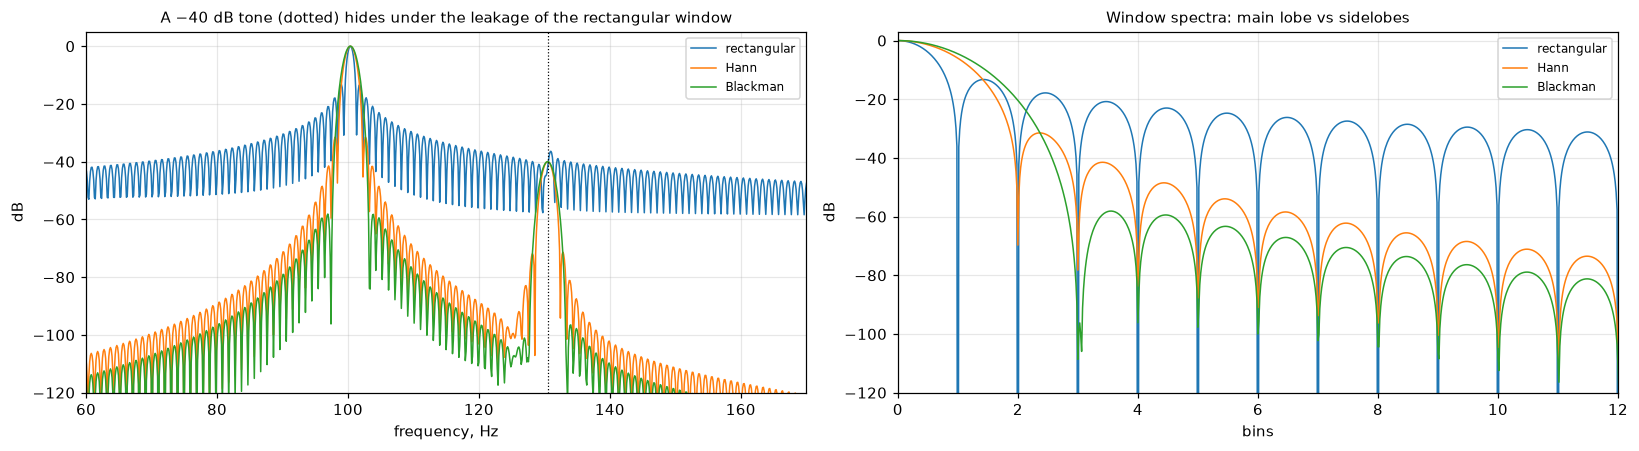

  rectangular   : sidelobe  -13.3 dB (theory  -13.3), first null at 1.00 bins, noise bandwidth ENBW 1.00 bins
  Hann          : sidelobe  -31.5 dB (theory  -31.5), first null at 2.00 bins, noise bandwidth ENBW 1.50 bins
  Blackman      : sidelobe  -58.1 dB (theory  -58.1), first null at 3.00 bins, noise bandwidth ENBW 1.73 bins
Convolution 16384 × 8192: direct 21 ms, via FFT 0.8 ms (27× faster), max difference 3.8e-13
Parseval: ‖x‖² = 16205.3690, ‖FFT(x)‖²/N = 16205.3690


In [3]:
# a strong tone off the bin centre and a weak tone at −40 dB, 30 Hz away
M1 = 1024; n1 = np.arange(M1)
x1 = np.cos(2 * np.pi * 100.37 * n1 / FS) + 1e-2 * np.cos(2 * np.pi * 130.5 * n1 / FS)
wins = {"rectangular": np.ones(M1), "Hann": np.hanning(M1), "Blackman": np.blackman(M1)}
th_sl = {"rectangular": -13.26, "Hann": -31.47, "Blackman": -58.11}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
f1 = np.fft.rfftfreq(8 * M1, 1 / FS)
rows = []
for (nm, w), c in zip(wins.items(), ("C0", "C1", "C2")):
    X = np.abs(np.fft.rfft(x1 * w, 8 * M1)) / (w.sum() / 2)
    ax[0].plot(f1, 20 * np.log10(X + 1e-12), c, lw=1, label=nm)
    W = np.abs(np.fft.rfft(w, 64 * M1)); W /= W[0]; Wd = 20 * np.log10(W + 1e-15)
    first_null = np.argmax(np.diff(Wd) > 0)                          # first minimum
    sl = Wd[first_null:].max()
    enbw = M1 * np.sum(w ** 2) / w.sum() ** 2
    ax[1].plot(np.arange(len(W)) / 64, Wd, c, lw=1, label=nm)
    rows.append((nm, sl, th_sl[nm], first_null / 64, enbw))
ax[0].axvline(130.5, color="k", ls=":", lw=0.8)
ax[0].set_xlim(60, 170); ax[0].set_ylim(-120, 5); ax[0].set_xlabel("frequency, Hz"); ax[0].set_ylabel("dB"); ax[0].legend(fontsize=8)
ax[0].set_title("A −40 dB tone (dotted) hides under the leakage of the rectangular window", fontsize=10)
ax[1].set_xlim(0, 12); ax[1].set_ylim(-120, 3); ax[1].set_xlabel("bins"); ax[1].set_ylabel("dB"); ax[1].legend(fontsize=8)
ax[1].set_title("Window spectra: main lobe vs sidelobes", fontsize=10)
plt.tight_layout(); plt.show()
for nm, sl, th, fn, eb in rows:
    print(f"  {nm:14s}: sidelobe {sl:6.1f} dB (theory {th:6.1f}), first null at {fn:.2f} bins, noise bandwidth ENBW {eb:.2f} bins")

# the convolution theorem: O(N log N) vs O(N²)
a, b = rng.standard_normal(2 ** 14), rng.standard_normal(2 ** 13)
tt0 = time.perf_counter(); c_dir = np.convolve(a, b); t_dir = time.perf_counter() - tt0
tt0 = time.perf_counter(); L = len(a) + len(b) - 1; c_fft = np.fft.irfft(np.fft.rfft(a, 2 ** 15) * np.fft.rfft(b, 2 ** 15))[:L]; t_fft = time.perf_counter() - tt0
print(f"Convolution 16384 × 8192: direct {t_dir*1e3:.0f} ms, via FFT {t_fft*1e3:.1f} ms ({t_dir/t_fft:.0f}× faster), max difference {np.abs(c_dir - c_fft).max():.1e}")
print(f"Parseval: ‖x‖² = {np.sum(a**2):.4f}, ‖FFT(x)‖²/N = {np.sum(np.abs(np.fft.fft(a))**2)/len(a):.4f}")

## 2. The uncertainty relation and the STFT
To see **when** a frequency is present, one takes a short window and slides it: the short-time Fourier transform (STFT, spectrogram). A window of length $T$ gives a frequency resolution of ~$1/T$. The product of RMS widths is bounded from below:
$$\sigma_t\,\sigma_f\ge\frac1{4\pi},$$
and equality holds only for the Gaussian window (check: 0.0796 = 1/4π). Hann and Blackman are close to the bound. For the rectangular window $\sigma_f$ is formally infinite: $\int f^2\,\mathrm{sinc}^2f\,df$ diverges because of the slow sidelobes. This is the same relation as in quantum mechanics, and the same Balian–Low theorem that gives OFDM its spectral tails (`ofdm_sim`, section 1).

Two windows on the same signal:
* **32 samples (32 ms)**: the clicks and the burst are thin vertical lines and the chirp is visible, but the 50 and 62 Hz tones merge into one wide band (Δf ≈ 62 Hz).
* **256 samples (256 ms)**: the tones are resolved (a 14.5 dB dip) and the chirp is thin, but the clicks are smeared over ±128 ms, and the burst becomes a blob.

The STFT window is chosen **once for all frequencies**. Signals where high frequencies are short and low ones long (speech, music, impacts, seismics) need a different window at different frequencies. That is what wavelets are.

  Gaussian (σ = L/8)    : σ_t·σ_f = 0.0796  (bound 1/4π = 0.0796)
  Hann                  : σ_t·σ_f = 0.0817  (bound 1/4π = 0.0796)
  Blackman              : σ_t·σ_f = 0.0799  (bound 1/4π = 0.0796)
  rectangular           : σ_t·σ_f = 1.2240  (bound 1/4π = 0.0796)
  for the rectangle σ_f grows with the frequency grid: ∫f²·sinc²(f) df diverges


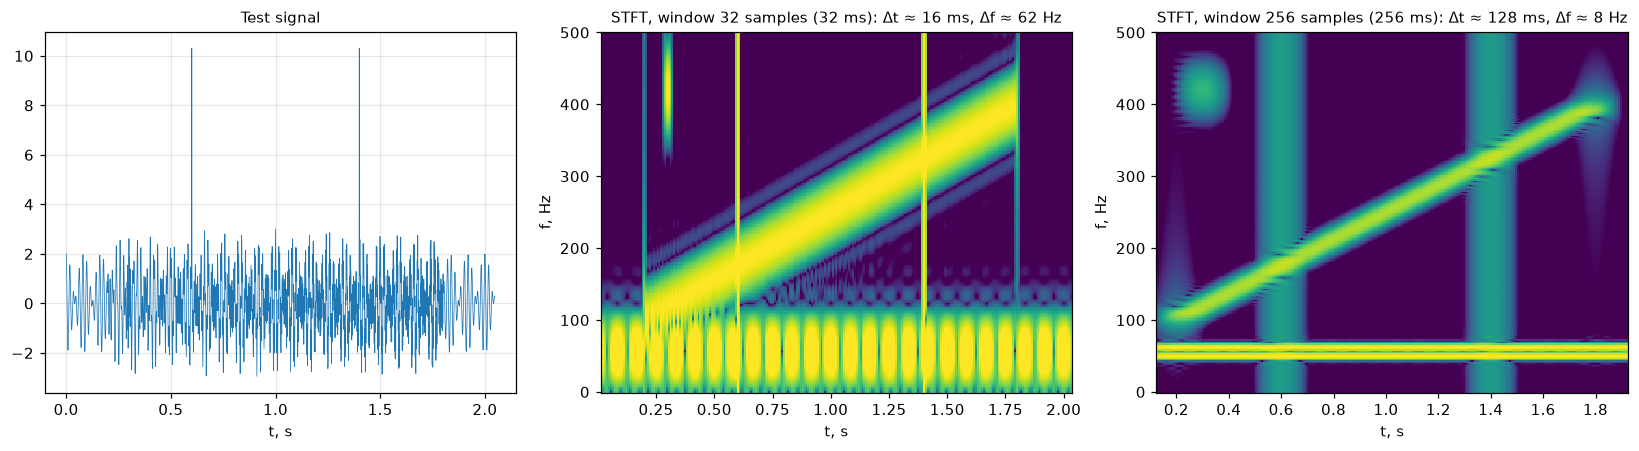

  window  32: dip between the tones    0.1 dB → merged
  window 128: dip between the tones   -2.1 dB → merged
  window 256: dip between the tones  -14.5 dB → resolved


In [4]:
# the uncertainty relation for windows
def spreads(w, pad=64):
    n = np.arange(len(w)) - (len(w) - 1) / 2; e = np.abs(w) ** 2
    st = np.sqrt(np.sum(n ** 2 * e) / e.sum())
    W = np.abs(np.fft.fft(w, pad * len(w))) ** 2; f = np.fft.fftfreq(pad * len(w))
    sf = np.sqrt(np.sum(f ** 2 * W) / W.sum())
    return st, sf
L2 = 256; nn = np.arange(L2) - (L2 - 1) / 2
for nm, w in (("Gaussian (σ = L/8)", np.exp(-nn ** 2 / (2 * (L2 / 8) ** 2))), ("Hann", np.hanning(L2)),
              ("Blackman", np.blackman(L2)), ("rectangular", np.ones(L2))):
    st, sf = spreads(w)
    print(f"  {nm:22s}: σ_t·σ_f = {st*sf:.4f}  (bound 1/4π = {1/(4*np.pi):.4f})")
print("  for the rectangle σ_f grows with the frequency grid: ∫f²·sinc²(f) df diverges")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(t, X_TEST, lw=0.5); ax[0].set_xlabel("t, s")
ax[0].set_title("Test signal", fontsize=10)
for a_, L in ((ax[1], 32), (ax[2], 256)):
    tt, ff, S = stft(X_TEST, L, 8)
    a_.pcolormesh(tt, ff, 20 * np.log10(S + 1e-3), vmin=-40, vmax=0, shading="auto", cmap="viridis"); a_.grid(False)
    a_.set_xlabel("t, s"); a_.set_ylabel("f, Hz")
    a_.set_title(f"STFT, window {L} samples ({L/FS*1e3:.0f} ms): Δt ≈ {L/FS*1e3/2:.0f} ms, Δf ≈ {2*FS/L:.0f} Hz", fontsize=10)
plt.tight_layout(); plt.show()

# resolving the two tones at 50 and 62 Hz
for L in (32, 128, 256):
    tt, ff, S = stft(X_TEST, L, 8, nfft=4096); prof = S[:, (tt > 1.85) & (tt < 2.0)].mean(1) if np.any((tt > 1.85) & (tt < 2.0)) else S[:, -1]
    p = prof[(ff >= 45) & (ff <= 67)]; f_ = ff[(ff >= 45) & (ff <= 67)]
    dip = p[(f_ > 54) & (f_ < 58)].min() / min(p[np.argmin(np.abs(f_ - 50))], p[np.argmin(np.abs(f_ - 62))])
    print(f"  window {L:3d}: dip between the tones {20*np.log10(dip):6.1f} dB → {'resolved' if dip < 0.7 else 'merged'}")

## 3. The continuous wavelet transform
Instead of one window there is one "small wave" function $\psi$, which is compressed and stretched:
$$W(s,b)=\frac1{\sqrt s}\int x(t)\,\psi^*\!\Big(\frac{t-b}s\Big)dt .$$
The Morlet wavelet is a Gaussian pulse with a carrier: $\psi(t)=e^{j\omega_0t}e^{-t^2/2}$. At scale $s$ it is tuned to frequency $f=\omega_0/2\pi s$ and has duration $\sigma_t=s$ and bandwidth $\sigma_f=f/\omega_0$. **The quality factor is constant**: $f/\sigma_f=\omega_0$. High frequencies are analysed with a short window, low ones with a long one. The tiles of the time–frequency plane all have the same area (the uncertainty relation cannot be beaten), but their shape depends on frequency (middle and right plots).

On the scalogram:
* **The clicks** are narrow at the top and wide at the bottom. The full width at half maximum is exactly $2.355\,\omega_0/2\pi f$: 7.5 ms at 300 Hz, 90 ms at 25 Hz.
* **The chirp** is a smooth curve; the ridge follows the instantaneous frequency to 0.6 %.
* **The 50 and 62 Hz tones** are not resolved at $\omega_0=6$: the bandwidth at 50 Hz is 8 Hz. Beats at the 12 Hz difference frequency are visible instead. A larger $\omega_0$ would resolve them but smear the clicks.

The CWT is redundant: here 140 scales × 2048 shifts for 2048 samples. That is convenient for analysis, but not for compression or transmission. The non-redundant version is the DWT.

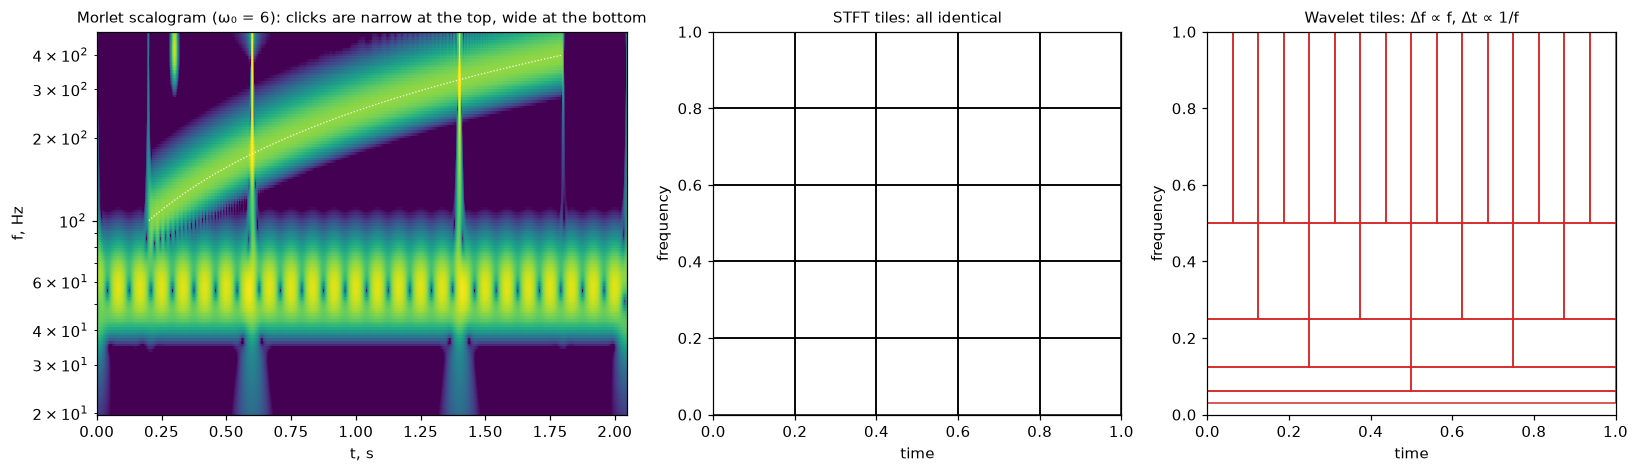

A 150 Hz tone of amplitude 1: |W| at 150 Hz = 1.000
  impulse at   300 Hz: full width at half maximum    7.5 ms (theory 2.355·ω₀/2πf =    7.5 ms), bandwidth σ_f = f/ω₀ =  50.0 Hz
  impulse at   100 Hz: full width at half maximum   22.5 ms (theory 2.355·ω₀/2πf =   22.5 ms), bandwidth σ_f = f/ω₀ =  16.7 Hz
  impulse at    25 Hz: full width at half maximum   89.9 ms (theory 2.355·ω₀/2πf =   90.0 ms), bandwidth σ_f = f/ω₀ =   4.2 Hz
The scalogram ridge follows the chirp's instantaneous frequency: median error 0.6 % (frequency grid step 2.3 %)
Redundancy: the CWT has 140×2048 complex coefficients for 2048 samples — 140× more data; the DWT (section 4) has exactly 2048


In [5]:
FREQS = np.geomspace(20, 480, 140)
Wc = cwt_morlet(X_TEST, FREQS)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax[0].pcolormesh(t, FREQS, 20 * np.log10(np.abs(Wc) + 1e-3), vmin=-30, vmax=6, shading="auto", cmap="viridis"); ax[0].grid(False)
ax[0].set_yscale("log"); ax[0].set_xlabel("t, s"); ax[0].set_ylabel("f, Hz")
ax[0].plot(t[(t > 0.2) & (t < 1.8)], f_inst(t[(t > 0.2) & (t < 1.8)]), "w:", lw=0.8)
ax[0].set_title(f"Morlet scalogram (ω₀ = {W0:g}): clicks are narrow at the top, wide at the bottom", fontsize=10)

# time–frequency tiles
for a_, kind in ((ax[1], "STFT"), (ax[2], "wavelet")):
    for j in range(5):
        if kind == "STFT":
            h_, w_ = 1 / 5, 1 / 5; y0 = j / 5
            for i in range(5): a_.add_patch(plt.Rectangle((i * w_, y0), w_, h_, fill=False, lw=1))
        else:
            h_ = 2.0 ** -(5 - j); y0 = h_; w_ = 1 / 2 ** j
            for i in range(2 ** j): a_.add_patch(plt.Rectangle((i * w_, y0), w_, h_, fill=False, lw=1, color="C3"))
    a_.set_xlim(0, 1); a_.set_ylim(0, 1); a_.set_xlabel("time"); a_.set_ylabel("frequency"); a_.grid(False)
    a_.set_title("STFT tiles: all identical" if kind == "STFT" else "Wavelet tiles: Δf ∝ f, Δt ∝ 1/f", fontsize=10)
plt.tight_layout(); plt.show()

# checks: tone amplitude, impulse width, chirp ridge
tone = np.cos(2 * np.pi * 150 * t)
print(f"A 150 Hz tone of amplitude 1: |W| at 150 Hz = {np.abs(cwt_morlet(tone, [150.0]))[0, 500:-500].mean():.3f}")
imp = np.zeros(N); imp[N // 2] = 1
for f in (300.0, 100.0, 25.0):
    w = np.abs(cwt_morlet(imp, [f]))[0]; w /= w.max(); tc = np.arange(N) / FS
    tf = np.linspace(tc[0], tc[-1], 40 * N); wf = np.interp(tf, tc, w)
    ab = tf[wf >= 0.5]; fwhm = ab[-1] - ab[0]                              # interpolated full width at half maximum
    print(f"  impulse at {f:5.0f} Hz: full width at half maximum {fwhm*1e3:6.1f} ms (theory 2.355·ω₀/2πf = {2.355*W0/(2*np.pi*f)*1e3:6.1f} ms), bandwidth σ_f = f/ω₀ = {f/W0:5.1f} Hz")
sel = (t > 0.45) & (t < 1.75) & (np.abs(t - 0.6) > 0.05) & (np.abs(t - 1.4) > 0.05)
hi = FREQS > 85
ridge = FREQS[hi][np.argmax(np.abs(Wc[hi][:, sel]), 0)]
print(f"The scalogram ridge follows the chirp's instantaneous frequency: median error {np.median(np.abs(ridge / f_inst(t[sel]) - 1))*100:.1f} % (frequency grid step {(FREQS[1]/FREQS[0]-1)*100:.1f} %)")
print(f"Redundancy: the CWT has {len(FREQS)}×{N} complex coefficients for {N} samples — {len(FREQS)}× more data; the DWT (section 4) has exactly {N}")

## 4. The discrete wavelet transform: a filter bank
The DWT (Mallat, Daubechies, 1988–89) takes only scales $2^j$ and shifts that are multiples of the scale, and this is an orthonormal basis. The implementation is **a pair of filters and decimation**: the low-pass filter $h$ gives a coarse version $a$, and the high-pass filter $g[n]=(-1)^nh[L-1-n]$ gives the details $d$. Both are decimated by 2, and the step is repeated on the coarse version. There are exactly as many output samples as input samples, reconstruction is exact (error $10^{-14}$), and energy is preserved. The complexity is $O(N)$ — faster than the FFT.

Why does the piecewise-smooth signal give so few significant coefficients (101 of 2048 above 1 % of the maximum)? **Vanishing moments**: the Daubechies wavelet db$p$ satisfies $\sum_nn^kg[n]=0$ for $k<p$. So a polynomial of degree below $p$ gives **zero** details. The table checks this: Haar zeroes only constants, db2 also linear functions, db4 polynomials up to degree 3 (degree 4 gives $10^{-9}$). Any smooth stretch is locally almost a polynomial, so its details are small. Large coefficients remain only where the signal is not smooth: at jumps and kinks. Their number grows like the logarithm of the length, not like the length. This is the whole secret of JPEG 2000 and wavelet denoising (section 7).

Fourier loses on the same signal: a step's spectrum decays as $1/k$, and its coefficients are spread over the whole band.

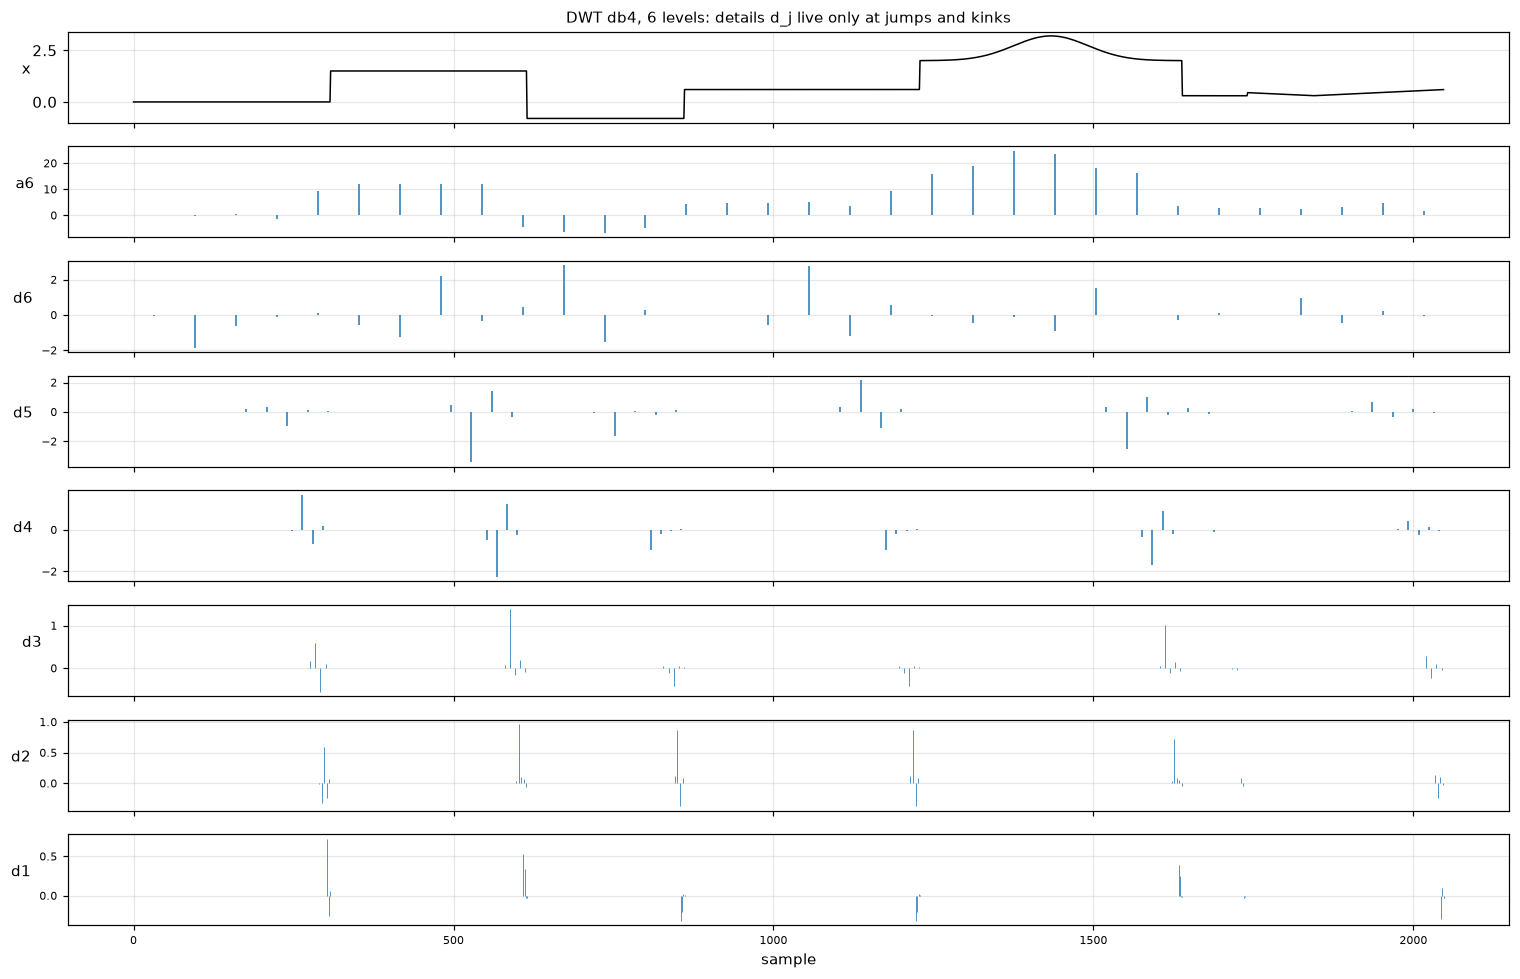

Orthogonality: ‖x‖² = 3531.918000, Σ‖coeff‖² = 3531.918000; reconstruction error 1.8e-14
Coefficients with |c| > 1 % of the maximum: 101 of 2048
max|d₁| in the interior for polynomials of degree 0…4:
  haar  (1 vanishing moments):  0.0e+00   2.8e-03   5.2e-03   7.3e-03   9.1e-03
  db2   (2 vanishing moments):  1.1e-16   1.7e-16   1.9e-05   5.3e-05   1.0e-04
  db4   (4 vanishing moments):  1.1e-16   2.2e-16   2.5e-16   3.1e-16   2.9e-09


In [6]:
# a piecewise-smooth signal: steps + a smooth bump + a kink
def piecewise():
    u = np.arange(N) / N
    y = np.select([u < 0.15, u < 0.3, u < 0.42, u < 0.6, u < 0.8], [0.0, 1.5, -0.8, 0.6, 2.0], 0.3)
    y = y + 1.2 * np.exp(-((u - 0.7) / 0.04) ** 2) + 3 * np.abs(u - 0.9) * (u > 0.85)
    return y
X_PW = piecewise()
LEV = 6
cs = wavedec(X_PW, "db4", LEV)
fig, ax = plt.subplots(LEV + 2, 1, figsize=(14, 9), sharex=True)
ax[0].plot(np.arange(N), X_PW, "k", lw=1); ax[0].set_ylabel("x", rotation=0)
ax[0].set_title(f"DWT db4, {LEV} levels: details d_j live only at jumps and kinks", fontsize=10)
names = [f"a{LEV}"] + [f"d{j}" for j in range(LEV, 0, -1)]
for a_, c, nm in zip(ax[1:], cs, names):
    pos = (np.arange(len(c)) + 0.5) * N / len(c)
    a_.vlines(pos, 0, c, lw=1 if len(c) < 200 else 0.5); a_.set_ylabel(nm, rotation=0, labelpad=12); a_.tick_params(labelsize=7)
ax[-1].set_xlabel("sample")
plt.tight_layout(); plt.show()

allc = np.concatenate(cs)
print(f"Orthogonality: ‖x‖² = {np.sum(X_PW**2):.6f}, Σ‖coeff‖² = {np.sum(allc**2):.6f}; reconstruction error {np.abs(waverec(cs, 'db4') - X_PW).max():.1e}")
print(f"Coefficients with |c| > 1 % of the maximum: {np.sum(np.abs(allc) > 0.01*np.abs(allc).max())} of {N}")

# vanishing moments: a polynomial of degree < p gives zero details (away from the periodization edge)
u = np.linspace(-1, 1, 512)
print("max|d₁| in the interior for polynomials of degree 0…4:")
for wl, p in (("haar", 1), ("db2", 2), ("db4", 4)):
    vals = []
    for deg in range(5):
        _, d = dwt_step(u ** deg, WAVELETS[wl]); vals.append(np.abs(d[8:-8]).max())
    print(f"  {wl:5s} ({p} vanishing moments): " + "  ".join(f"{v:8.1e}" for v in vals))

## 5. Fresnel in optics: diffraction by a slit
The Fresnel transform comes from optics. The field behind an aperture at distance $z$ in the paraxial approximation is
$$u(x,z)\propto\int u_0(x')\,e^{\,j\pi(x-x')^2/\lambda z}\,dx'=u_0*\text{chirp}\quad\Longleftrightarrow\quad U(f,z)=U_0(f)\,e^{-j\pi\lambda zf^2}.$$
This is **convolution with a chirp**, or equivalently multiplying the spectrum by a quadratic phase. Numerically it is one FFT pair. For a slit of width $2a$ there is an exact answer via the Fresnel integrals $C(\nu)$, $S(\nu)$, and the numerical result matches it: RMS error $10^{-5}$–$10^{-4}$ of the peak (2 % maximum right at the edge in the near field, where the oscillations are finest).

The regime is set by the **Fresnel number** $N_F=a^2/\lambda z$:
* $N_F\gg1$ — near field: an almost geometric shadow with ripples at the edges;
* $N_F\sim1$ — the Fresnel region: a complex pattern, neither shadow nor spectrum;
* $N_F\ll1$ — far field, **Fraunhofer**: expand $(x-x')^2=x^2-2xx'+x'^2$; the term $x'^2/\lambda z$ is small over the aperture (phase $\pi N_F$), and the integral becomes **the Fourier transform of the aperture**: $I\propto\mathrm{sinc}^2(2ax/\lambda z)$. At $N_F=0.5$ the difference from sinc² is 20 %, at $N_F=0.05$ it is 0.2 %.

So **Fourier is a limiting case of Fresnel**: the far field and the focal plane of a lens are an optical spectrum analyser. Formally $\text{Fresnel}=\text{chirp}\cdot\text{Fourier}\cdot\text{chirp}$.

  N_F =    10: z =  0.039 m, error vs Fresnel integrals: RMS 4.5e-04, max 2.2e-02 of the peak; difference from Fraunhofer nan
  N_F =     2: z =  0.197 m, error vs Fresnel integrals: RMS 4.7e-05, max 1.8e-03 of the peak; difference from Fraunhofer nan
  N_F =   0.5: z =  0.790 m, error vs Fresnel integrals: RMS 1.4e-05, max 2.0e-04 of the peak; difference from Fraunhofer 2.0e-01
  N_F =  0.05: z =  7.899 m, error vs Fresnel integrals: RMS 3.3e-05, max 6.7e-05 of the peak; difference from Fraunhofer 2.2e-03


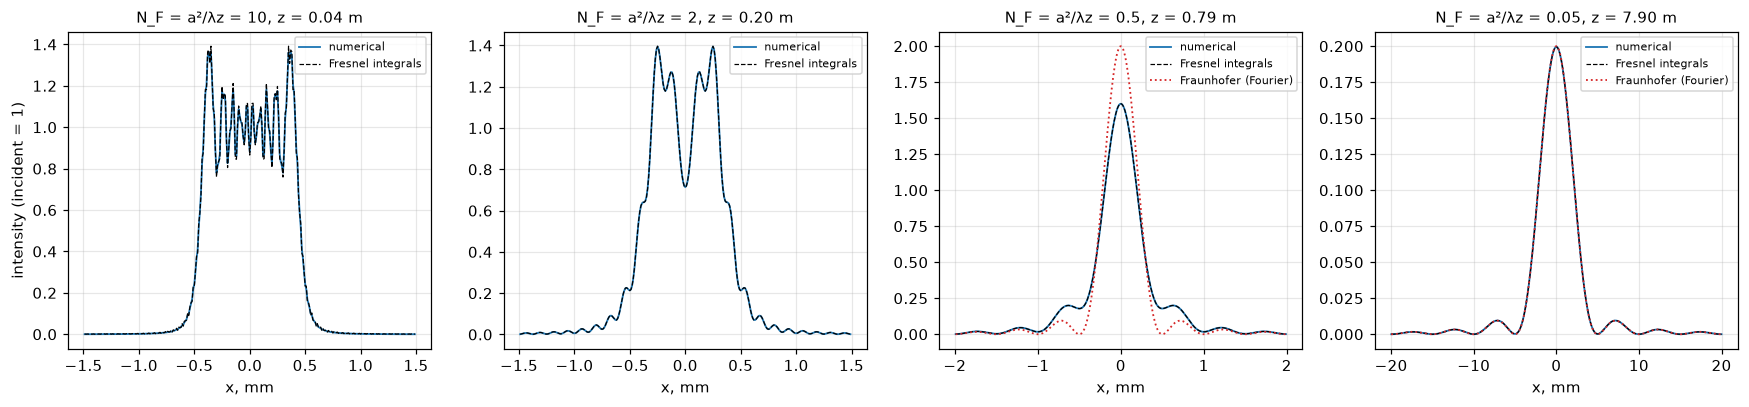

At N_F = 0.05 the chirp exp(jπx²/λz) rotates the phase at the slit edge by π·N_F = 0.16 rad → it can be dropped, leaving the plain Fourier transform of the aperture


In [7]:
# diffraction by a slit of width 2a: numerical (chirp in the spectrum) vs Fresnel integrals
NX, DX = 2 ** 16, 10e-6
xg = (np.arange(NX) - NX // 2) * DX
u0 = (np.abs(xg) <= SLIT_A + 1e-12).astype(complex)
u0[np.isclose(np.abs(xg), SLIT_A)] = 0.5                           # the slit edge falls on a sample: weight ½ (trapezoid rule)
def slit_analytic(x, z, a=SLIT_A):
    k = np.sqrt(2 / (LAM * z)); S1, C1 = fresnel(k * (-a - x)); S2, C2 = fresnel(k * (a - x))
    return 0.5 * ((C2 - C1) ** 2 + (S2 - S1) ** 2)
NFs = [10, 2, 0.5, 0.05]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a_, nf in zip(ax, NFs):
    z = SLIT_A ** 2 / (LAM * nf)
    I = np.abs(fresnel_prop(u0, DX, z)) ** 2; Ia = slit_analytic(xg, z)
    span = max(3 * SLIT_A, 4 * LAM * z / (2 * SLIT_A)); m = np.abs(xg) < span
    a_.plot(xg[m] * 1e3, I[m], "C0", lw=1.2, label="numerical"); a_.plot(xg[m] * 1e3, Ia[m], "k--", lw=0.8, label="Fresnel integrals")
    if nf < 1:
        Ifr = (2 * SLIT_A) ** 2 / (LAM * z) * np.sinc(2 * SLIT_A * xg / (LAM * z)) ** 2
        a_.plot(xg[m] * 1e3, Ifr[m], "C3:", lw=1.2, label="Fraunhofer (Fourier)")
        err_fr = np.abs(I[m] - Ifr[m]).max() / Ifr.max()
    else:
        err_fr = np.nan
    a_.set_xlabel("x, mm"); a_.legend(fontsize=7)
    a_.set_title(f"N_F = a²/λz = {nf:g}, z = {z:.2f} m", fontsize=10)
    print(f"  N_F = {nf:5g}: z = {z:6.3f} m, error vs Fresnel integrals: RMS {np.sqrt(np.mean((I - Ia)**2))/Ia.max():.1e}, max {np.abs(I - Ia).max()/Ia.max():.1e} of the peak; difference from Fraunhofer {err_fr:.1e}")
ax[0].set_ylabel("intensity (incident = 1)")
plt.tight_layout(); plt.show()

# Fraunhofer as a special case: Fresnel = chirp · Fourier · chirp
z = SLIT_A ** 2 / (LAM * 0.05)
ch = np.exp(1j * np.pi * xg ** 2 / (LAM * z))
print(f"At N_F = 0.05 the chirp exp(jπx²/λz) rotates the phase at the slit edge by π·N_F = {np.pi*0.05:.2f} rad → it can be dropped, leaving the plain Fourier transform of the aperture")

## 6. Discrete Fresnel: the Talbot effect and chirp → delta
**The Talbot effect** (1836) is the most vivid manifestation of a quadratic phase. A periodic grating with period $d$ consists of harmonics $m/d$. Each one picks up a phase $e^{-j\pi\lambda zm^2/d^2}$ as it propagates. At distance $z_T=2d^2/\lambda$ this phase equals $e^{-j2\pi m^2}=1$ **for all $m$ at once**, and the grating reproduces itself without a lens. At $z_T/2$ the phase is $(-1)^{m^2}=(-1)^m$ — a copy shifted by half a period. In between lies a "carpet" of fractional copies. Numerically the revival is exact: $10^{-16}$.

**The discrete Fresnel transform** (DFnT) is the same operation on a grid of $N$ samples: $\Phi=F^H\Gamma F$, $\Gamma=\mathrm{diag}(e^{-j\pi k^2/N})$. Its basis functions are discrete chirps $e^{-j\pi(n-m)^2/N}$ with shift $m$. This is exactly the OCDM basis (`ocdm_sim`), and AFDM (`afdm_sim`) is the same DFnT with a tunable chirp rate. Hence:
* **a matched chirp** is a single basis function; the DFnT gathers it into one coefficient (100 % of the energy), while the DFT spreads it evenly over all bins;
* **a chirp with rate 0.8/N** is no longer a basis function: the DFnT compresses it only partly, into a "shelf" of ~45 samples. Fresnel is compression of a chirp pulse by a **matched** filter, as in radar and in the LoRa demodulator (`lora_sim`).

Fresnel transforms form a group: $\Phi_\alpha\Phi_\beta=\Phi_{\alpha+\beta}$ — propagating over $z_1$ and then over $z_2$ is the same as propagating over $z_1+z_2$. Fourier in this family is "infinite distance", and the fractional Fourier transform (FrFT) connects them continuously.

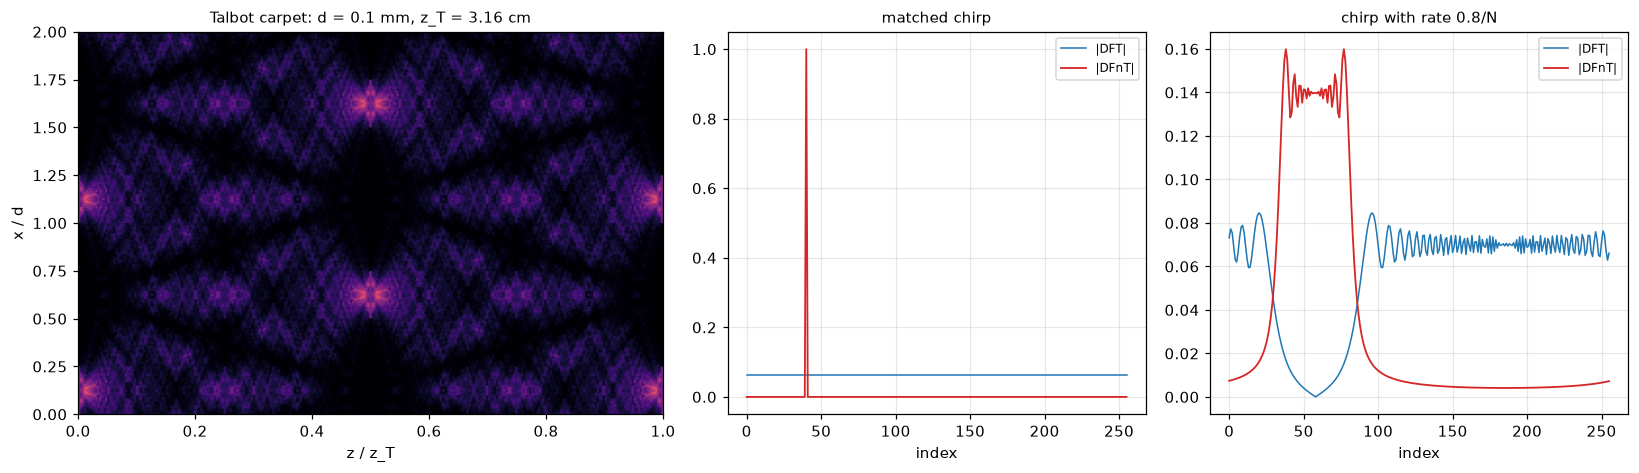

Talbot: max|I(z_T) − I(0)| = 2.2e-16; at z_T/2 the pattern is shifted by half a period: error 4.4e-16
  reason: harmonic m of the grating gets the phase exp(−jπλz·m²/d²), which at z_T equals exp(−j2πm²) = 1 for all m
Energy fraction in one coefficient: matched chirp — DFT 0.004, DFnT 1.000 (at index 40); mismatched — DFnT 0.026
Fresnel is a group: Φ_α·Φ_β = Φ_(α+β), max error 3.4e-15; propagating over z₁ and then z₂ = over z₁ + z₂


In [8]:
# the Talbot effect: a periodic grating reproduces itself at z_T = 2d²/λ
PER, SPP = 8, 256
NT = PER * SPP; dxt = GRAT_D / SPP
xt = np.arange(NT) * dxt
grat = ((np.arange(NT) % SPP) < SPP // 4).astype(complex)               # slits of width d/4
zT = 2 * GRAT_D ** 2 / LAM
zs = np.linspace(0, zT, 301)
carpet = np.array([np.abs(fresnel_prop(grat, dxt, z)) ** 2 for z in zs])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax[0].imshow(carpet[:, :2 * SPP].T, aspect="auto", origin="lower", extent=[0, 1, 0, 2], cmap="magma", vmax=3); ax[0].grid(False)
ax[0].set_xlabel("z / z_T"); ax[0].set_ylabel("x / d")
ax[0].set_title(f"Talbot carpet: d = {GRAT_D*1e3:g} mm, z_T = {zT*100:.2f} cm", fontsize=10)
I0 = np.abs(grat) ** 2
err_T = np.abs(carpet[-1] - I0).max()
err_half = np.abs(carpet[150] - np.roll(I0, SPP // 2)).max()

# the discrete Fresnel transform: chirp → delta
M6 = 256; n6 = np.arange(M6)
chirp_m = np.exp(-1j * np.pi * (n6 - 40) ** 2 / M6) / np.sqrt(M6)       # a chirp with rate exactly 1/N, shift 40
chirp_x = np.exp(-1j * np.pi * 0.8 * (n6 - 40) ** 2 / M6) / np.sqrt(M6)  # rate 0.8/N — mismatched
for a_, sig, nm in ((ax[1], chirp_m, "matched chirp"), (ax[2], chirp_x, "chirp with rate 0.8/N")):
    a_.plot(n6, np.abs(np.fft.fft(sig)) / np.sqrt(M6), "C0", lw=1, label="|DFT|")
    a_.plot(n6, np.abs(dfnt(sig)), "C3", lw=1.2, label="|DFnT|")
    a_.set_xlabel("index"); a_.legend(fontsize=8); a_.set_title(nm, fontsize=10)
plt.tight_layout(); plt.show()

print(f"Talbot: max|I(z_T) − I(0)| = {err_T:.1e}; at z_T/2 the pattern is shifted by half a period: error {err_half:.1e}")
print(f"  reason: harmonic m of the grating gets the phase exp(−jπλz·m²/d²), which at z_T equals exp(−j2πm²) = 1 for all m")
pk = lambda c: np.max(np.abs(c) ** 2) / np.sum(np.abs(c) ** 2)
print(f"Energy fraction in one coefficient: matched chirp — DFT {pk(np.fft.fft(chirp_m)):.3f}, DFnT {pk(dfnt(chirp_m)):.3f} (at index {np.argmax(np.abs(dfnt(chirp_m)))}); mismatched — DFnT {pk(dfnt(chirp_x)):.3f}")
print(f"Fresnel is a group: Φ_α·Φ_β = Φ_(α+β), max error {np.abs(dfnt(dfnt(chirp_x, 0.3), 0.5) - dfnt(chirp_x, 0.8)).max():.1e}; propagating over z₁ and then z₂ = over z₁ + z₂")

## 7. Each basis has its own signal: sparsity and denoising
Three signal classes, three orthonormal bases. For each pair:
* **K99** — how many of the largest coefficients carry 99 % of the energy (fewer means better compression);
* **denoising**: noise at SNR 5 dB, then every coefficient with $|c|<\sigma\sqrt{2\ln N}$ is zeroed (the Donoho–Johnstone threshold, the same for all bases) and the inverse transform is taken.

Both numbers are the same property. An orthonormal basis turns white noise into white noise with the same $\sigma$, so the noise spreads evenly over **all** $N$ coefficients. A signal in its "own" basis is concentrated in a few large coefficients, and the threshold separates them from the noise. In a "foreign" basis the signal is smeared over thousands of small coefficients drowning in the noise, and the threshold kills it along with the noise.

The diagonal of the table wins everywhere: tones — Fourier (25 coefficients, 17 dB), steps — wavelets (46, 14.9 dB), chirp — Fresnel (1 coefficient, 34 dB). No basis is universal. This is why in communications the waveform is chosen for the channel (`ofdm_sim` vs `ocdm_sim` vs `otfs_sim`), and in compression for the class of images (DCT in JPEG, wavelets in JPEG 2000).

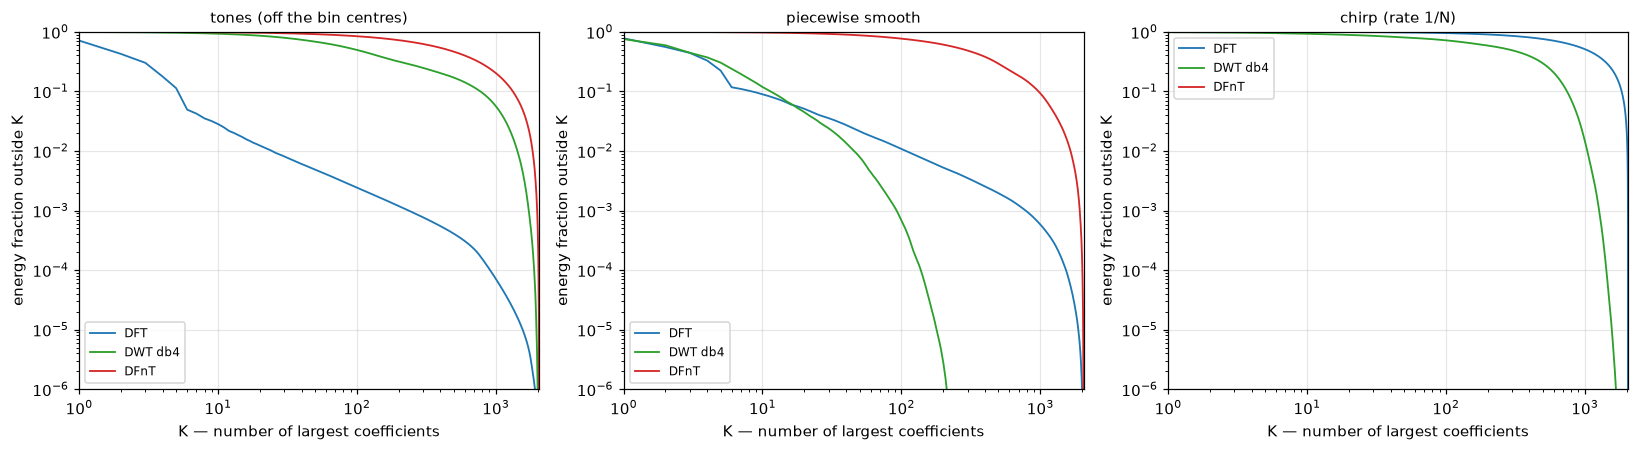

Number of coefficients for 99 % of the energy (of 2048) and SNR after thresholding (input 5 dB):
                                           DFT           DWT db4              DFnT
tones (off the bin centres)      25 /  17.0 dB     1431 /   3.2 dB     1842 /   0.4 dB  
piecewise smooth                108 /  13.0 dB       46 /  14.9 dB     1652 /   1.1 dB  
chirp (rate 1/N)               2028 /  -0.0 dB     1043 /   1.0 dB        1 /  34.0 dB  


In [9]:
# three signal classes × three orthonormal bases: sparsity and denoising
u = np.arange(N)
SIGS = {
    "tones (off the bin centres)": np.cos(2 * np.pi * 50.3 * t) + 0.7 * np.cos(2 * np.pi * 120.7 * t) + 0.5 * np.cos(2 * np.pi * 333.1 * t),
    "piecewise smooth": X_PW - X_PW.mean(),
    "chirp (rate 1/N)": np.exp(-1j * np.pi * (u - 300) ** 2 / N),
}
def to_c(x, kind):
    if kind == "DFT": return np.fft.fft(x) / np.sqrt(N)
    if kind == "DWT db4": return np.concatenate(wavedec(x, "db4", 8))
    return dfnt(x)
def from_c(c, kind):
    if kind == "DFT": return np.fft.ifft(c) * np.sqrt(N)
    if kind == "DWT db4":
        sizes = [N >> 8] + [N >> j for j in range(8, 0, -1)]; parts = np.split(c, np.cumsum(sizes)[:-1])
        return waverec(parts, "db4")
    return idfnt(c)
KINDS = ["DFT", "DWT db4", "DFnT"]
SNR_IN = 5
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
K99 = np.zeros((3, 3), int); SNRo = np.zeros((3, 3))
for i, ((nm, x), a_) in enumerate(zip(SIGS.items(), ax)):
    px = np.mean(np.abs(x) ** 2); sig = np.sqrt(px / 10 ** (SNR_IN / 10))
    cplx = np.iscomplexobj(x)
    noise = sig * (rng.standard_normal(N) + 1j * rng.standard_normal(N)) / np.sqrt(2) if cplx else sig * rng.standard_normal(N)
    for j, (kd, c_) in enumerate(zip(KINDS, ("C0", "C2", "C3"))):
        c = to_c(x.astype(complex), kd); e = np.sort(np.abs(c) ** 2)[::-1]; ce = np.cumsum(e) / e.sum()
        K99[i, j] = np.searchsorted(ce, 0.99) + 1
        a_.loglog(np.arange(1, N + 1), np.maximum(1 - ce, 1e-12), c_, lw=1.2, label=kd)
        cn = to_c((x + noise).astype(complex), kd)
        cn = np.where(np.abs(cn) > sig * np.sqrt(2 * np.log(N)), cn, 0)    # hard threshold σ√(2 ln N)
        xr = from_c(cn, kd); xr = xr if cplx else xr.real
        SNRo[i, j] = 10 * np.log10(px / np.mean(np.abs(xr - x) ** 2))
    a_.set_ylim(1e-6, 1); a_.set_xlim(1, N); a_.set_xlabel("K — number of largest coefficients")
    a_.set_ylabel("energy fraction outside K"); a_.legend(fontsize=8); a_.set_title(nm, fontsize=10)
plt.tight_layout(); plt.show()

print(f"Number of coefficients for 99 % of the energy (of {N}) and SNR after thresholding (input {SNR_IN} dB):")
print(f"{'':28s}" + "".join(f"{k:>18s}" for k in KINDS))
for i, nm in enumerate(SIGS):
    print(f"{nm:28s}" + "".join(f"{K99[i, j]:7d} / {SNRo[i, j]:5.1f} dB  " for j in range(3)))

## Comparison

| | Fourier (DFT) | STFT | CWT (Morlet) | DWT (Daubechies) | Fresnel (DFnT) |
|---|---|---|---|---|---|
| basis | sinusoids | sinusoids × window | stretched wavelets | dyadic wavelets | chirps |
| orthonormal | yes | no (a frame) | no (redundant) | yes | yes |
| coefficients per $N$ samples | $N$ | $N\cdot$(overlap) | $N\cdot$(number of scales) | $N$ | $N$ |
| complexity | $N\log N$ | $N\log L$ per frame | $N\log N$ per scale | $N$ | $N\log N$ |
| time–frequency tiles | whole band × whole time | identical | $\Delta f\propto f$ | $\Delta f\propto f$, dyadic | tilted (along the chirp) |
| makes sparse | tones | — | — | piecewise smooth | chirps |
| diagonalizes | LTI channels (convolution) | — | — | — | optical propagation |
| in communications | OFDM, OFDMA | spectrograms, analysis | analysis, radar | wavelet OFDM (PLC), compression | OCDM, AFDM, LoRa |

**The main point.**
- All five answer one question: which reference signals to decompose into.
- Fourier diagonalizes **convolution**, so an LTI channel in it is just a multiplication, and OFDM is built on Fourier.
- Fresnel diagonalizes **a quadratic phase**, so it compresses chirps and describes diffraction.
- Wavelets diagonalize nothing, but they **adapt resolution** to scale and make sparse the signals that are smooth everywhere except at a few points.

## Things to try
- In section 1, move the weak tone to 101.5 Hz: no window separates it, because it sits inside the main lobe of the strong tone.
- `W0 = 12`: the 50 and 62 Hz tones get resolved on the scalogram, but the clicks smear twice as wide. `W0 = 3` does the opposite.
- In section 4, replace `"db4"` with `"haar"`: the steps are described even more compactly (Haar is itself a step), but the bump and the kink get worse; compare K99.
- `SLIT_A = 2e-3`: at the same $N_F$ all distances grow 16×, and the patterns are the same — this is the scale invariance of Fresnel.
- `GRAT_D = 0.2e-3`: the Talbot distance grows 4×, since $z_T\propto d^2$.
- In section 7, denoise with a DFnT of a different `alpha`: see how quickly the chirp's sparsity falls apart under mismatch.